In [22]:
import torch
import torch
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)
print("cuDNN Version:", torch.backends.cudnn.version())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")


PyTorch Version: 2.5.1
CUDA Available: True
CUDA Version: 12.4
cuDNN Version: 90100
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [23]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset,DataLoader
import torch.nn as nn
import torch

In [24]:
torch.manual_seed(42)

In [25]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [26]:
df=pd.read_csv('fmnist_small.csv')
df

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1,0,0,0,0,0,0,0,0,0,...,69,12,0,0,0,0,0,0,0,0
5996,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5997,8,0,0,0,0,0,0,0,0,0,...,39,47,2,0,0,29,0,0,0,0
5998,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [27]:
df.shape

(6000, 785)

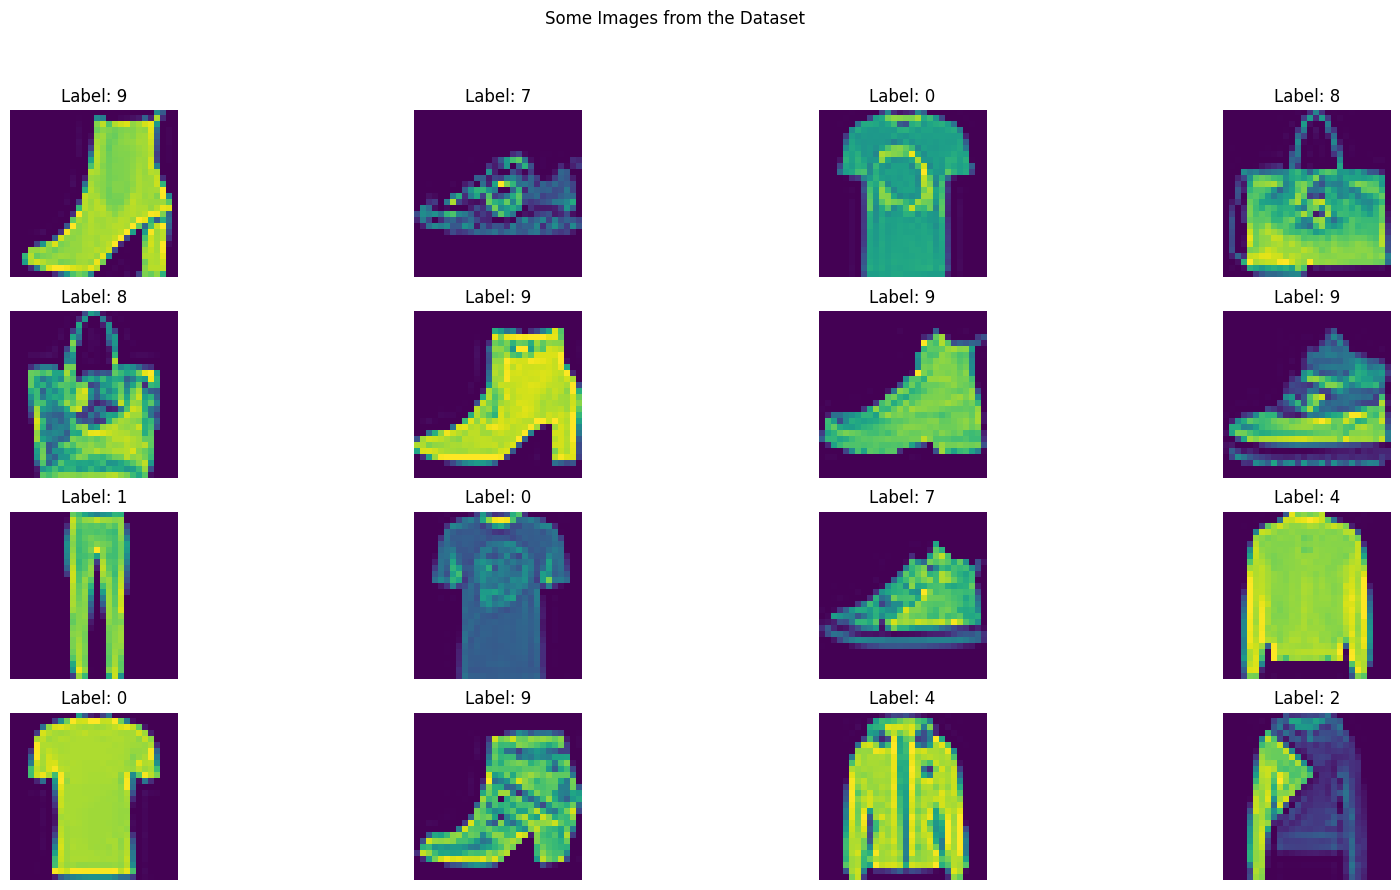

In [28]:
fig,axes=plt.subplots(4,4,figsize=(20,10))
fig.suptitle('Some Images from the Dataset')
for i ,ax in enumerate(axes.flat):
    img=df.iloc[i,1:].values.reshape(28,28)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f'Label: {df.iloc[i,0]}')

In [29]:
# tarin test split
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

In [30]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
x_train = x_train/255.0
x_test = x_test/255.0

In [32]:
class CustomDataset(Dataset):
    
    def __init__(self,features,labels):
        self.features = torch.tensor(features, dtype=torch.float32).reshape(-1,1,28,28) # batch size, channel, height, width
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]
    

In [33]:
train_dataset = CustomDataset(x_train, y_train)

In [34]:
test_dataset = CustomDataset(x_test, y_test)

In [35]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)


In [36]:
class MyNN(nn.Module):

    def __init__(self,input_features):
        super().__init__()

        self.features=  nn.Sequential(
            nn.Conv2d(in_channels=1,out_channels=32,kernel_size=3,padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(kernel_size=2,stride=2),



        )
        self.classifier= nn.Sequential(

            nn.Flatten(),
            nn.Linear(64*7*7,128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64,10)
        )  
    def forward(self,x):
        x=self.features(x)
        x=self.classifier(x)
        return x

In [37]:
learning_rate = 0.01
epochs = 100

In [38]:
model=MyNN(1).to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate,weight_decay=1e-4)

In [39]:
# training loop

for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')


Epoch: 1 , Loss: 1.3297623825073241
Epoch: 2 , Loss: 0.8809899099667867
Epoch: 3 , Loss: 0.7448904456694921
Epoch: 4 , Loss: 0.6775866109132767
Epoch: 5 , Loss: 0.6850170745452245
Epoch: 6 , Loss: 0.6195798829197884
Epoch: 7 , Loss: 0.5888615970810255
Epoch: 8 , Loss: 0.5900619002183278
Epoch: 9 , Loss: 0.6050004433592161
Epoch: 10 , Loss: 0.5855787219603856
Epoch: 11 , Loss: 0.5746140064795812
Epoch: 12 , Loss: 0.5692038199305535
Epoch: 13 , Loss: 0.5428221480051676
Epoch: 14 , Loss: 0.5456936667362849
Epoch: 15 , Loss: 0.5533118122816085
Epoch: 16 , Loss: 0.5162233798702558
Epoch: 17 , Loss: 0.506900035738945
Epoch: 18 , Loss: 0.5273196148375671
Epoch: 19 , Loss: 0.48423662841320037
Epoch: 20 , Loss: 0.5059396948417028
Epoch: 21 , Loss: 0.5507274682323138
Epoch: 22 , Loss: 0.5198328937093417
Epoch: 23 , Loss: 0.5390654401977857
Epoch: 24 , Loss: 0.5435898928840955
Epoch: 25 , Loss: 0.6323446123798688
Epoch: 26 , Loss: 0.648915405968825
Epoch: 27 , Loss: 0.5834125767151515
Epoch: 28 ,

In [40]:
model.eval()

MyNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [41]:
# evaluation code for test set
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.8416666666666667


In [42]:

# evaluation code
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.916875
